<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/Aidl_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from torch.utils.data import TensorDataset, DataLoader

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving student-por.csv to student-por (1).csv


In [ ]:
df = pd.read_csv("student-por.csv")

In [ ]:
df = pd.read_csv("student-por.csv")

In [ ]:
print(df.head())

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns)

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]

Shape: (649, 33)

Columns:
Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatu

In [ ]:
# Convert categorical columns into numerical values
df = pd.get_dummies(df, drop_first=True)

# Target
y = df["G3"]

# Features
X = df.drop("G3", axis=1)

# Standardization
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Convert to Tensor
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)
y_test = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

# DataLoader
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset,
                          batch_size=32,
                          shuffle=True)

test_loader = DataLoader(test_dataset,
                         batch_size=32,
                         shuffle=False)

print("Preprocessing Completed")

Preprocessing Completed


In [ ]:
class StudentModel(nn.Module):

    def __init__(self, input_size):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size,128),
            nn.ReLU(),

            nn.Linear(128,64),
            nn.ReLU(),

            nn.Linear(64,32),
            nn.ReLU(),

            nn.Linear(32,1)

        )

    def forward(self,x):
        return self.network(x)

input_size = X_train.shape[1]

model = StudentModel(input_size)

print(model)

StudentModel(
  (network): Sequential(
    (0): Linear(in_features=41, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
epochs = 100

train_losses = []

for epoch in range(epochs):

    model.train()

    running_loss = 0

    for features, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(features)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    if (epoch+1) % 10 == 0:

        print(f"Epoch {epoch+1}/{epochs} Loss = {epoch_loss:.4f}")

Epoch 10/100 Loss = 2.0546
Epoch 20/100 Loss = 1.1017
Epoch 30/100 Loss = 0.6405
Epoch 40/100 Loss = 0.3188
Epoch 50/100 Loss = 0.1412
Epoch 60/100 Loss = 0.0671
Epoch 70/100 Loss = 0.0366
Epoch 80/100 Loss = 0.0214
Epoch 90/100 Loss = 0.0095
Epoch 100/100 Loss = 0.0056


In [ ]:
model.eval()

predictions = []

actual = []

with torch.no_grad():

    for features, labels in test_loader:

        outputs = model(features)

        predictions.extend(outputs.numpy())

        actual.extend(labels.numpy())

predictions = np.array(predictions)

actual = np.array(actual)

print("Testing Completed")

Testing Completed


In [ ]:
mse = mean_squared_error(actual, predictions)

mae = mean_absolute_error(actual, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(actual, predictions)

print("========== Evaluation ==========")

print("MAE :", mae)

print("MSE :", mse)

print("RMSE :", rmse)

print("R² Score :", r2)

========== Evaluation ==========
MAE : 1.2450692653656006
MSE : 2.8738644123077393
RMSE : 1.6952475961663356
R² Score : 0.705296516418457


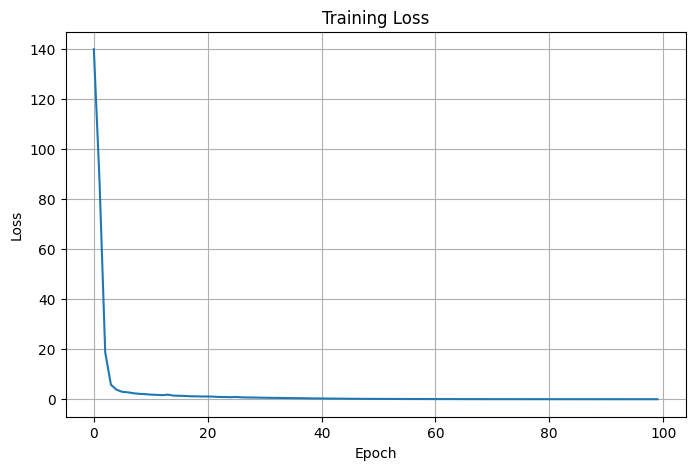

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(train_losses)

plt.title("Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

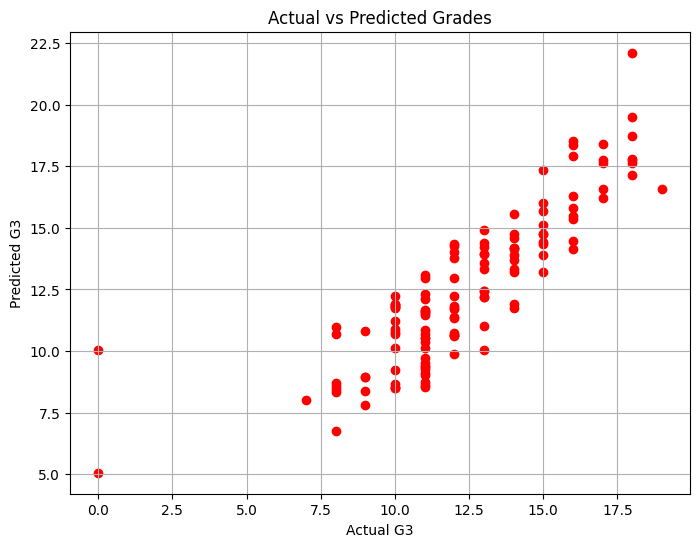

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(actual,
            predictions,
            color="red")

plt.xlabel("Actual G3")

plt.ylabel("Predicted G3")

plt.title("Actual vs Predicted Grades")

plt.grid(True)

plt.show()

In [ ]:
torch.save(model.state_dict(),"student_model.pth")

print("Model Saved Successfully")

Model Saved Successfully
